## Recurrent Porto Taxi Operating Routes (Flag 10)

### Dataset Overview
A constructed Porto Taxi case spanning two working weeks. It contains 140 road-aligned passenger trajectories: 105 distributed across recurrent corridors and 35 spatially diverse background trips. The trip table and GPS points support identifying route structure, orientation, occurrence time, and request-source composition.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Analyze recurrent operating routes in the provided Porto taxi trajectories and summarize their spatial, temporal, and passenger-request characteristics.

Role: Urban taxi operations analyst


Category: Recurrent route structure and passenger-request behavior

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectories.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: What recurrent movement corridors can be identified from the spatial shapes of the provided taxi trajectories, and which trips do not belong to these recurring patterns?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

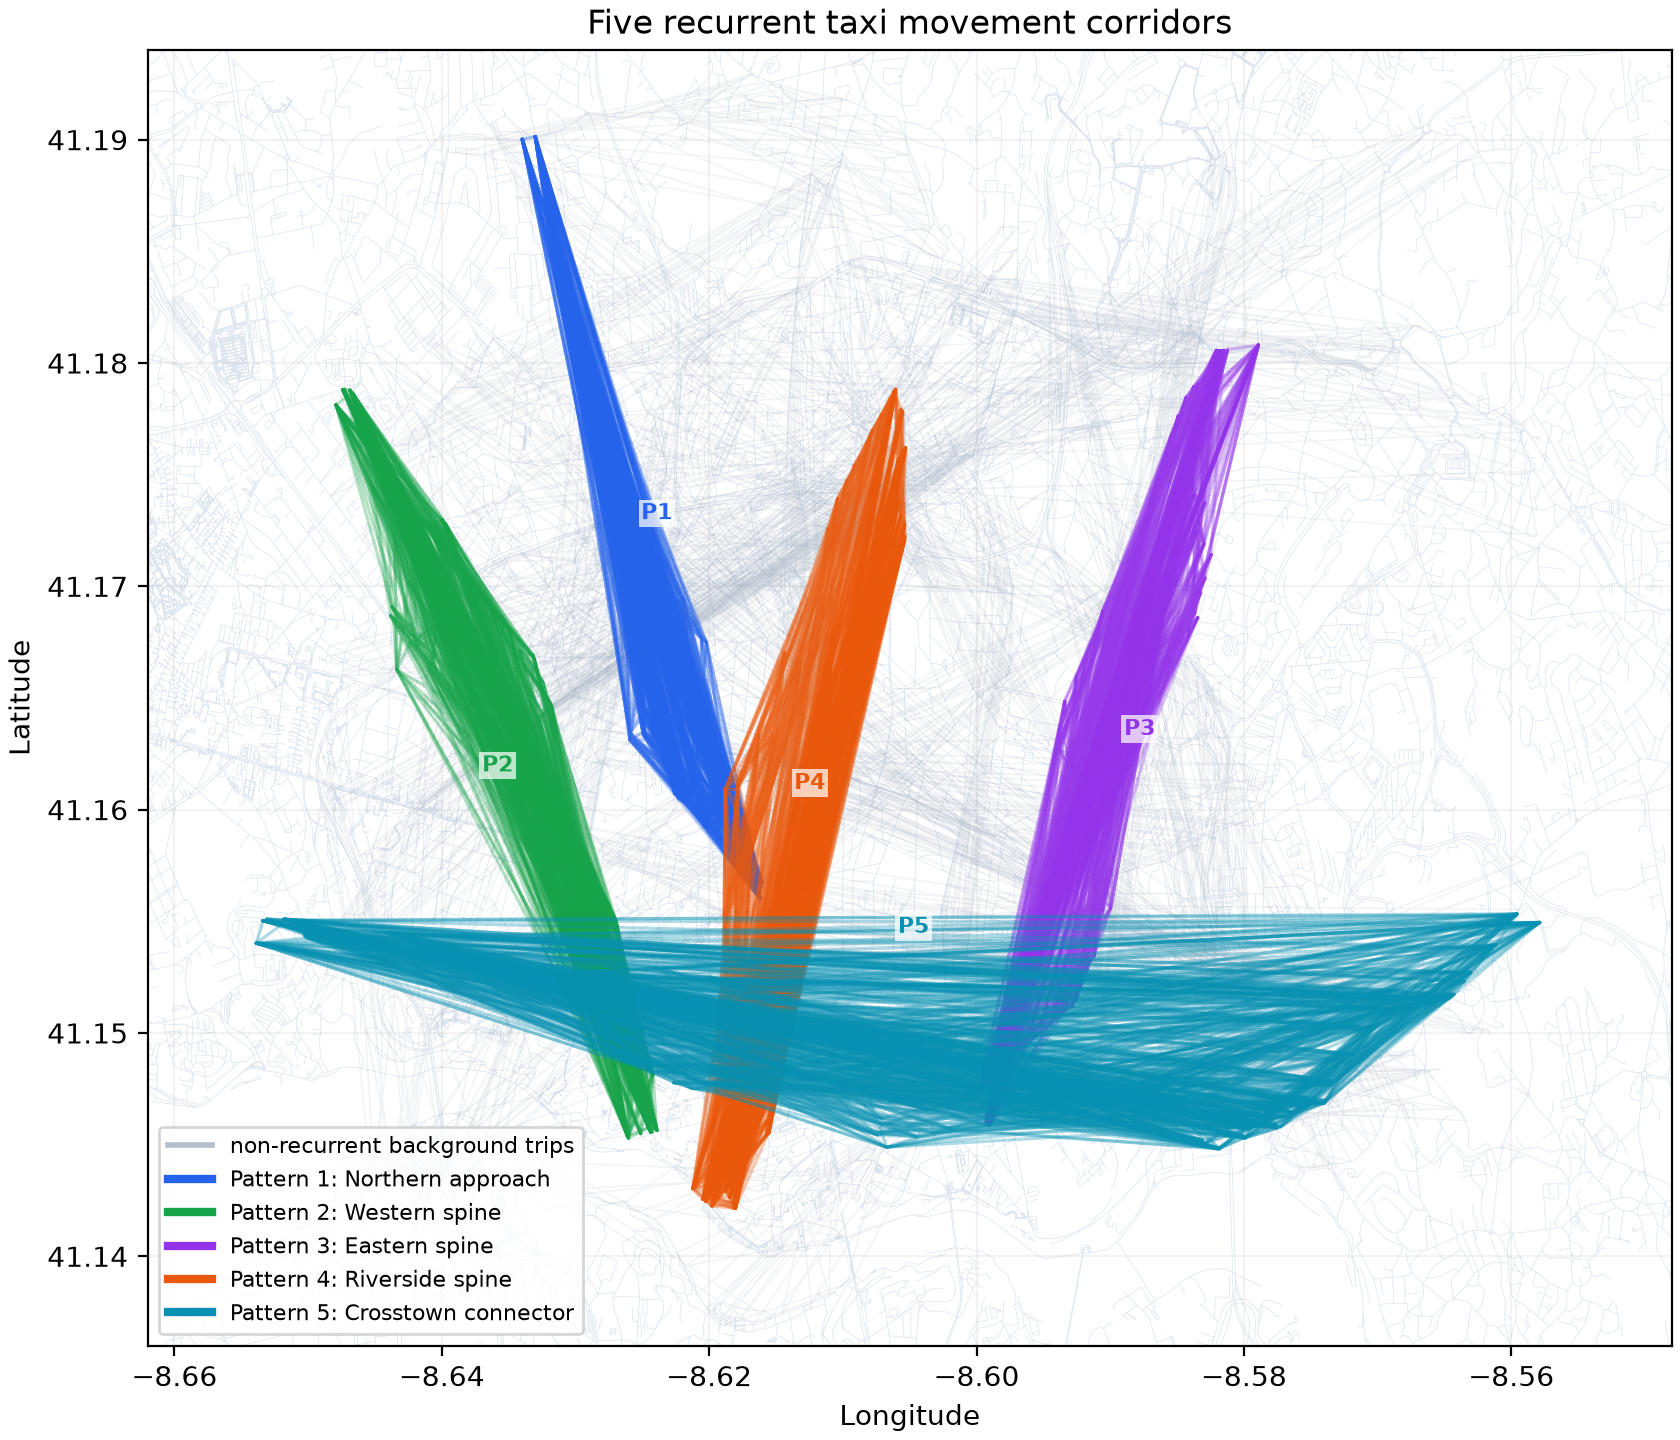

In [ ]:
# Cluster trajectories from trajectory_points.csv by spatial similarity, then map the resulting clusters.
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/five_recurrent_spatial_corridors.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (2 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "recurrent_spatial_trajectory_patterns",
  "insight": "Five recurrent trajectory patterns can be identified in the provided taxi traces, each representing a repeatedly observed movement corridor in Porto.",
  "plot": {
    "plot_type": "road_network_trajectory_cluster_map",
    "file": "visualizations/five_recurrent_spatial_corridors.png",
    "title": "Five Recurrent Taxi Movement Corridors",
    "description": "Road-aligned trajectories reveal five repeatedly occupied movement corridors against a diverse non-recurrent background."
  },
  "question": "What recurrent movement corridors can be identified from the spatial shapes of the provided taxi trajectories, and which trips do not belong to these recurring patterns?",
  "code": "# Cluster trajectories from trajectory_points.csv by spatial similarity, then map the resulting clusters.",
  "insight_type": "overall_pattern",
  "difficulty_level": 2,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_id"
  ]
}

### **Question 2**: How does the dominant orientation of each recurrent trajectory pattern compare across the identified corridors?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

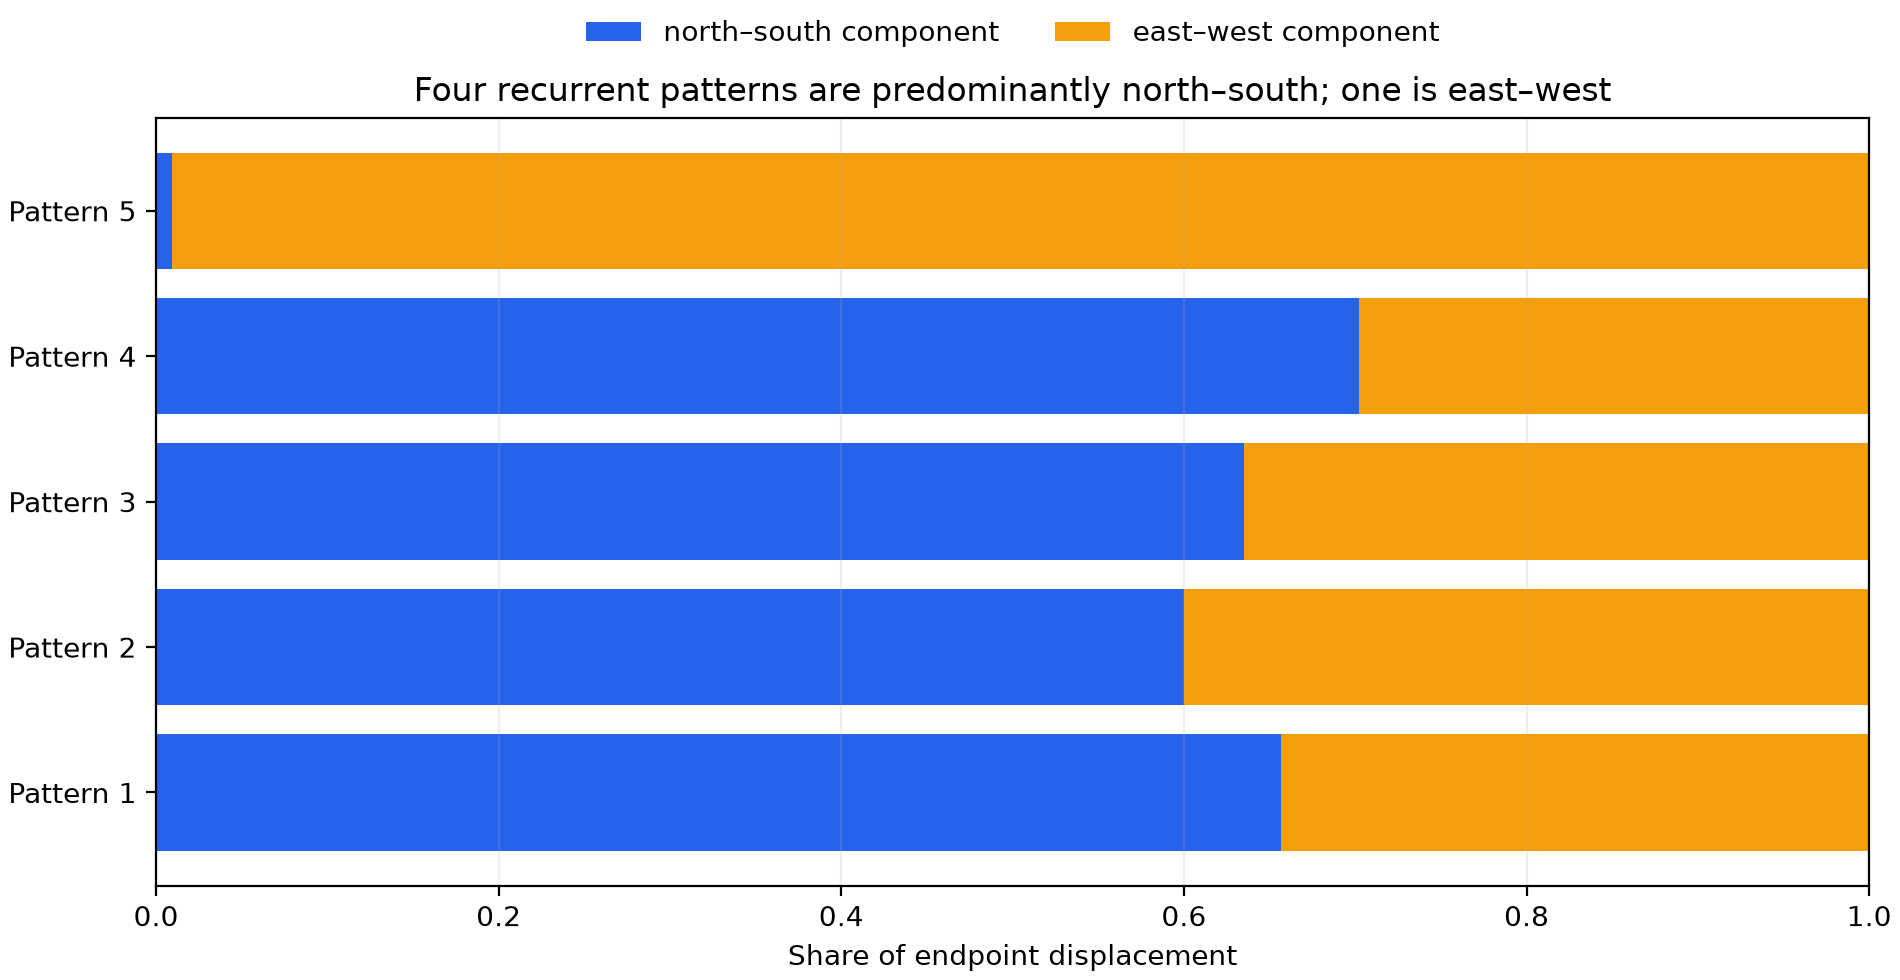

In [ ]:
d=df.copy(); d['dx']=(d.destination_longitude-d.origin_longitude).abs(); d['dy']=(d.destination_latitude-d.origin_latitude).abs(); print(d[['dx','dy']].describe())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/recurrent_pattern_orientation_components.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (2 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "trajectory_orientation_structure",
  "insight": "Four of the five recurrent trajectory patterns are predominantly north–south oriented, whereas the remaining pattern is predominantly east–west oriented.",
  "plot": {
    "plot_type": "stacked_orientation_component_chart",
    "file": "visualizations/recurrent_pattern_orientation_components.png",
    "title": "Orientation of Recurrent Taxi Patterns",
    "description": "Endpoint-displacement components distinguish north–south from east–west recurrent corridors."
  },
  "question": "How does the dominant orientation of each recurrent trajectory pattern compare across the identified corridors?",
  "code": "d=df.copy(); d['dx']=(d.destination_longitude-d.origin_longitude).abs(); d['dy']=(d.destination_latitude-d.origin_latitude).abs(); print(d[['dx','dy']].describe())",
  "insight_type": "group_comparison",
  "difficulty_level": 2,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_id"
  ]
}

### **Question 3**: When during weekdays does each recurrent trajectory pattern occur, and do the patterns separate into morning and evening groups?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

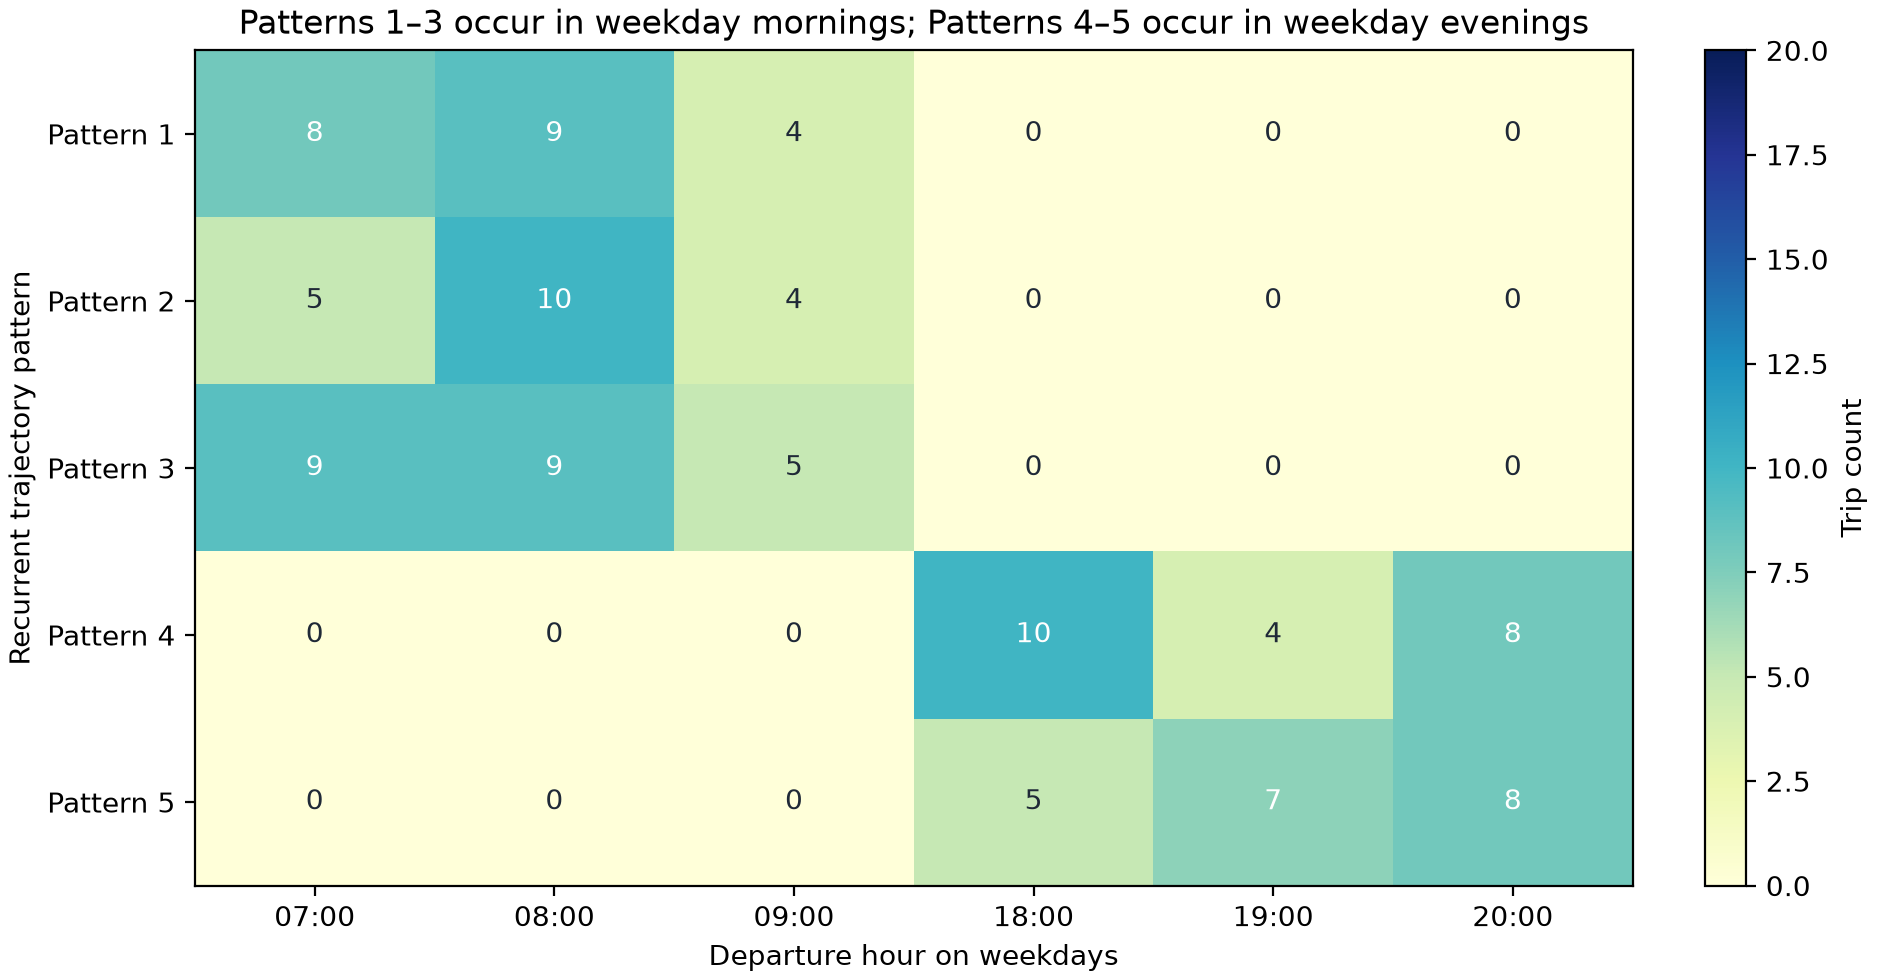

In [ ]:
d=df.copy(); d['hour']=pd.to_datetime(d.departure_time).dt.hour; print(d.groupby('hour').size())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/weekday_temporal_preferences.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "recurrent_pattern_temporal_segmentation",
  "insight": "The recurrent patterns have distinct temporal preferences: Patterns 1–3 occur predominantly on weekday mornings, while Patterns 4–5 are concentrated on weekday evenings.",
  "plot": {
    "plot_type": "pattern_by_hour_heatmap",
    "file": "visualizations/weekday_temporal_preferences.png",
    "title": "Weekday Temporal Preferences of Recurrent Patterns",
    "description": "The heatmap compares when the inferred route patterns occur on weekdays."
  },
  "question": "When during weekdays does each recurrent trajectory pattern occur, and do the patterns separate into morning and evening groups?",
  "code": "d=df.copy(); d['hour']=pd.to_datetime(d.departure_time).dt.hour; print(d.groupby('hour').size())",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "departure_time",
    "trajectory_id"
  ]
}

### **Question 4**: Do passenger request types differ across the recurrent movement patterns, or are their call-type compositions similar?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

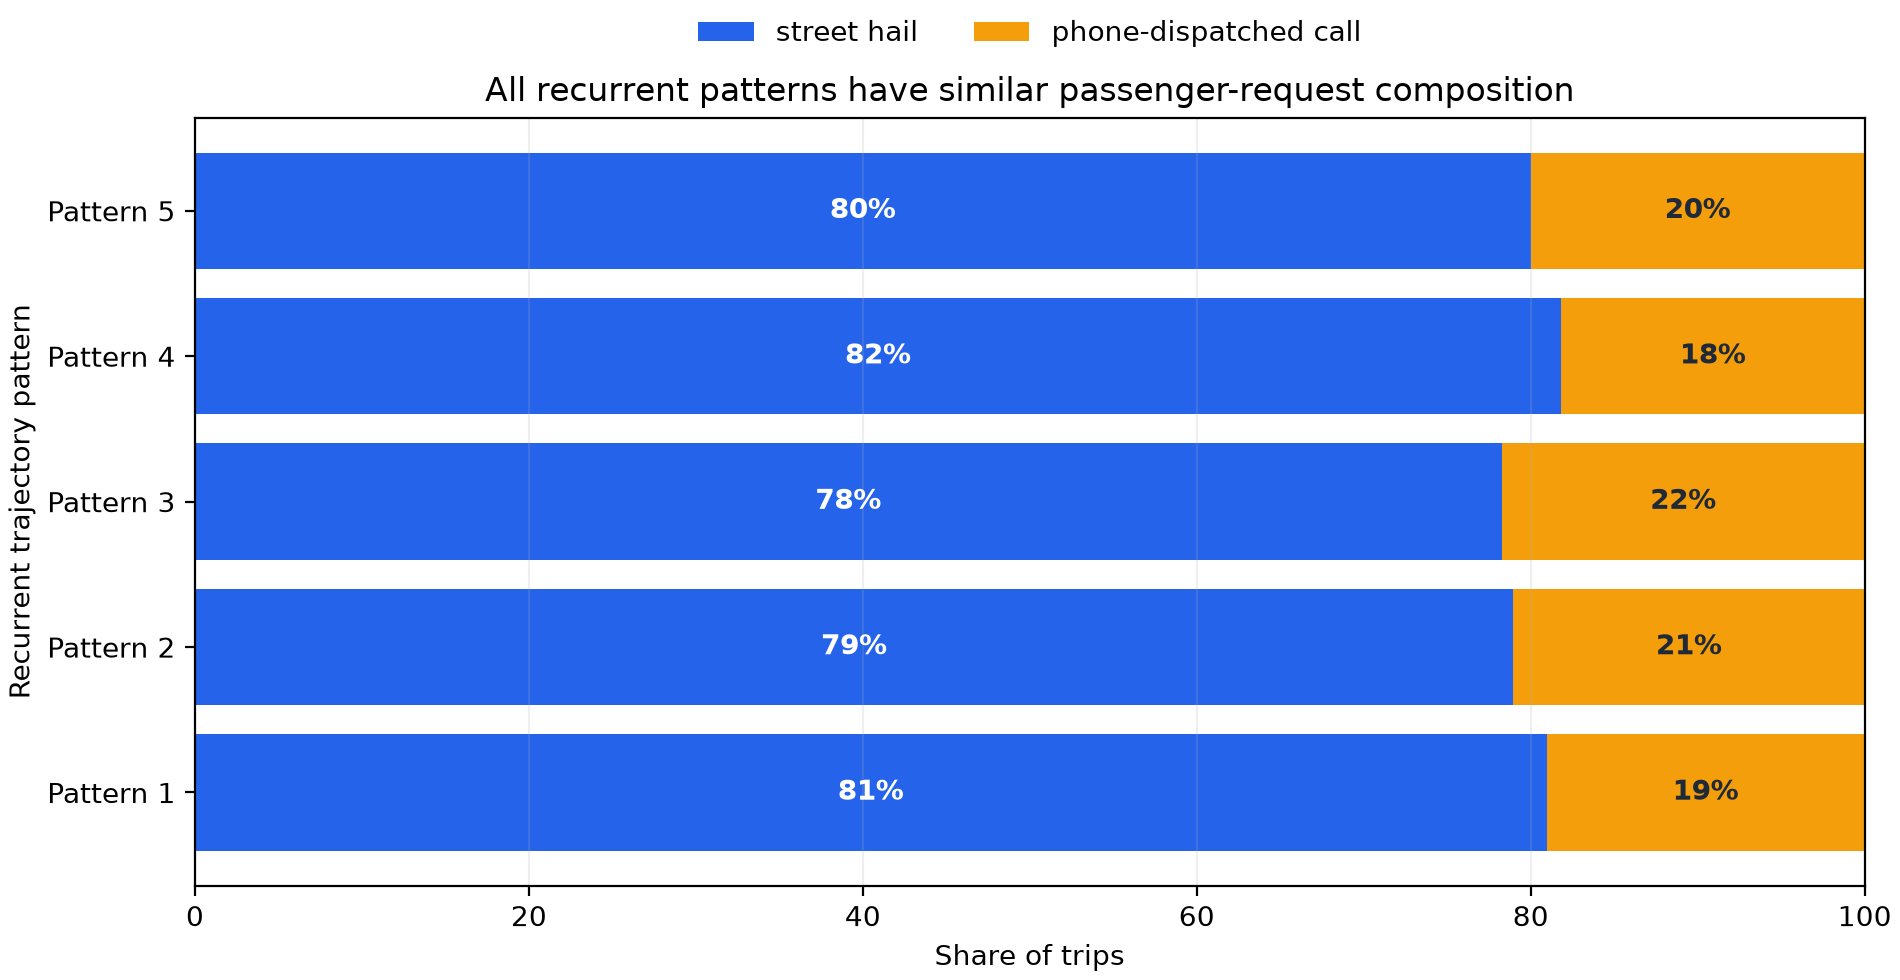

In [ ]:
print(df.groupby('call_type').size())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/call_type_distribution_by_pattern.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "passenger_request_source_comparison",
  "insight": "All five recurrent patterns have similar passenger-request compositions: approximately 80% of trips originate from street hails and 20% from phone-dispatched calls.",
  "plot": {
    "plot_type": "pattern_level_100_percent_stacked_bar_chart",
    "file": "visualizations/call_type_distribution_by_pattern.png",
    "title": "Passenger Request Types Across Recurrent Patterns",
    "description": "Each inferred corridor is compared by street-hail and phone-dispatched request shares."
  },
  "question": "Do passenger request types differ across the recurrent movement patterns, or are their call-type compositions similar?",
  "code": "print(df.groupby('call_type').size())",
  "insight_type": "group_comparison",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "request_source",
    "trajectory_id"
  ]
}

### Summary of Findings (Flag 10)

The trajectories organize into five recurring operating corridors. Four are predominantly north–south, while the east–west crosstown corridor is the remaining pattern. Patterns 1–3 are concentrated in weekday mornings, whereas Patterns 4–5 occur in weekday evenings. Across the corridors, passenger-request composition remains street-hail dominant and similar.